# Engine walkthrough — check every part yourself

The companion to `ml_walkthrough.ipynb`, for the **non-ML parts** of
Component 3. Each part runs on the proposal's wedding (plus a concurrent
corporate launch), shows the result, **checks it by hand**, and then
**breaks something on purpose** to show the system catches it.

Run cells top to bottom with **Shift + Enter**. Check cells print PASS, and stop with an
error if a check fails.

| Part | What you check |
|---|---|
| 1 | Planning engine (CP-SAT): every rule checked by hand; impossible pins named; a broken schedule caught; PSPLIB |
| 2 | Digital twin: late check-ins and missing check-ins, with tolerance |
| 3 | Cascade simulation (SimPy): undisturbed day and a 20-minute overrun |
| 4 | Re-optimisation: the photographer case, the shared-crew case, an impossible lock |
| 5 | Disruption evaluation: strategies compared, "delay absorbed" computed by hand |
| 6 | The live service: proposal, confirmation, audit log, cost signal, stale proposals |
| 7 | Scalability: 5 events × 30 activities against the 5-second limit |

### 0 · Setup (run this first)
Same as the ML notebook: on your laptop it finds the project folder; in
Google Colab it downloads the branch from GitHub, installs the libraries and
restarts once (then run this cell again).

In [1]:
import os, sys, subprocess
REPO = "https://github.com/fernandoshamod/J26-IT-383.git"
BRANCH = "event-planning-dynamic-resource-optimization/dinuja"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    target = "/content/J26-IT-383"
    if not os.path.exists(target):
        subprocess.run(["git", "clone", "--depth", "1", "-b", BRANCH, REPO, target], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{target}/requirements.txt",
                        "xgboost==3.4.1", "scikit-learn==1.9.1"], check=True)
        print("Installed. Restarting the session once — then run this cell again.")
        os.kill(os.getpid(), 9)
    os.chdir(target)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Project folder:", os.getcwd())

Project folder: C:\Users\ASUS\Desktop\SLIIT\4.1\reserch\research


In [2]:
import time, copy
from dataclasses import replace
import pandas as pd
import matplotlib.pyplot as plt
from api.scenario import build_demo_events, new_operations, play_on_time, scenario_kwargs
from examples.run_example import build_resources
from scheduling_engine.solver import solve_planning_phase
from scheduling_engine.conflict_detection import verify_schedule
from scheduling_engine.twin import OperationalDigitalTwin, CheckIn, CheckInType
from scheduling_engine.simulation import simulate_cascade
from scheduling_engine.reoptimization import reoptimize
pd.set_option("display.width", 160)
hm = lambda m: f"{int(m) // 60:02d}:{int(m) % 60:02d}"
print("ready")

ready


## 1 · Planning engine (CP-SAT)

**The input.** Two events on one shared timeline: the 11-activity wedding
(guest arrival fixed at 14:00 by the client) and a corporate launch fixed at
10:30. They share the florist and the AV crew.

In [3]:
events = build_demo_events()
resources = build_resources()
acts = [a for e in events for a in e.activities]
pd.DataFrame([dict(event=a.event_id, activity=a.id, minutes=a.duration_minutes,
                   needs=", ".join(f"{r.count}× {r.role}" for r in a.requirements),
                   after=", ".join(a.predecessors) or "—",
                   fixed=hm(a.fixed_start_minutes) if a.fixed_start_minutes is not None else "",
                   earliest=hm(a.earliest_start_minutes) if a.earliest_start_minutes else "") for a in acts])

,event,activity,minutes,needs,after,fixed,earliest
0,wedding,venue_setup,90,2× setup_crew,—,,08:00
1,wedding,decor,60,1× florist,venue_setup,,
2,wedding,sound_check,30,1× av_crew,venue_setup,,
3,wedding,catering_load_in,45,2× catering_crew,decor,,
4,wedding,guest_arrival,30,1× usher,"decor, sound_check",14:00,
5,wedding,ceremony,30,"1× officiant, 1× photographer",guest_arrival,,
6,wedding,photos,45,1× photographer,ceremony,,
7,wedding,dinner_service,60,2× catering_crew,"photos, catering_load_in",,
8,wedding,speeches,20,1× av_crew,dinner_service,,
9,wedding,entertainment,90,1× av_crew,speeches,,


In [4]:
pd.DataFrame([dict(id=r.id, role=r.role, type=r.type.value, turnaround_min=r.min_turnaround_minutes) for r in resources])

,id,role,type,turnaround_min
0,setup-1,setup_crew,staff,0
1,setup-2,setup_crew,staff,0
2,florist-1,florist,vendor,0
3,av-1,av_crew,staff,10
4,catering-1,catering_crew,vendor,0
5,catering-2,catering_crew,vendor,0
6,usher-1,usher,staff,0
7,officiant-1,officiant,vendor,0
8,photographer-1,photographer,vendor,0


**Solve it.** CP-SAT returns a start time and assigned resources for every activity.

In [5]:
t = time.perf_counter()
schedule = solve_planning_phase(events, resources)
print(f"status {schedule.status_name} | solved in {time.perf_counter() - t:.3f} s")
plan = pd.DataFrame([dict(activity=aid, start=hm(s.start_minutes), end=hm(s.end_minutes),
                          resources=", ".join(s.assigned_resource_ids), _s=s.start_minutes)
                     for aid, s in schedule.activities.items()]).sort_values("_s").drop(columns="_s")
plan

status OPTIMAL | solved in 0.010 s


,activity,start,end,resources
0,venue_setup,08:00,09:30,"setup-1, setup-2"
11,corp_decor,09:00,09:45,florist-1
2,sound_check,09:30,10:00,av-1
1,decor,09:45,10:45,florist-1
12,corp_event,10:30,12:30,av-1
3,catering_load_in,10:45,11:30,"catering-1, catering-2"
4,guest_arrival,14:00,14:30,usher-1
5,ceremony,14:30,15:00,"officiant-1, photographer-1"
6,photos,15:00,15:45,photographer-1
7,dinner_service,15:45,16:45,"catering-1, catering-2"


**Check every rule by hand** — not with the project's verifier, just plain
Python over the table above.

In [6]:
S = schedule.activities
by_id = {a.id: a for a in acts}
res_by_id = {r.id: r for r in resources}

# Rule 1 — precedence: every activity starts after all its predecessors end.
for a in acts:
    for p in a.predecessors:
        assert S[a.id].start_minutes >= S[p].end_minutes, (p, a.id)
print("PASS: precedence: every activity starts after its predecessors end")

# Rule 2 — the right resources: each requirement gets exactly `count` resources of that role.
for a in acts:
    for req in a.requirements:
        got = [r for r in S[a.id].assigned_resource_ids if res_by_id[r].role == req.role]
        assert len(got) == req.count, (a.id, req.role)
print("PASS: allocation: every requirement got the right number of the right role")

# Rule 3 — no double-booking, including turnaround: per resource, sort its jobs and
# check each one starts after the previous one ends PLUS the turnaround.
for r in resources:
    jobs = sorted((S[aid].start_minutes, S[aid].end_minutes, aid) for aid in S if r.id in S[aid].assigned_resource_ids)
    for (s1, e1, a1), (s2, e2, a2) in zip(jobs, jobs[1:]):
        assert s2 >= e1 + r.min_turnaround_minutes, (r.id, a1, a2)
print("PASS: no resource is double-booked, and turnaround gaps are respected")

# Rule 4 — fixed times are kept exactly.
for a in acts:
    if a.fixed_start_minutes is not None:
        assert S[a.id].start_minutes == a.fixed_start_minutes, a.id
print("PASS: fixed times kept: guest arrival 14:00, corporate launch 10:30")

# The project's independent verifier must agree.
assert verify_schedule(acts, resources, S) == []
print("PASS: independent verifier: 0 conflicts")

PASS: precedence: every activity starts after its predecessors end
PASS: allocation: every requirement got the right number of the right role
PASS: no resource is double-booked, and turnaround gaps are respected
PASS: fixed times kept: guest arrival 14:00, corporate launch 10:30
PASS: independent verifier: 0 conflicts


**See the AV crew work for both events** — one physical crew, two clients, no overlap, 10-minute turnaround between jobs.

In [7]:
for r in ("av-1", "florist-1"):
    jobs = sorted((S[aid].start_minutes, S[aid].end_minutes, aid, by_id[aid].event_id) for aid in S if r in S[aid].assigned_resource_ids)
    print(r + ":", " → ".join(f"{a} [{ev}] {hm(s)}-{hm(e)}" for s, e, a, ev in jobs))

av-1: sound_check [wedding] 09:30-10:00 → corp_event [corp_launch] 10:30-12:30 → speeches [wedding] 16:45-17:05 → entertainment [wedding] 17:15-18:45
florist-1: corp_decor [corp_launch] 09:00-09:45 → decor [wedding] 09:45-10:45


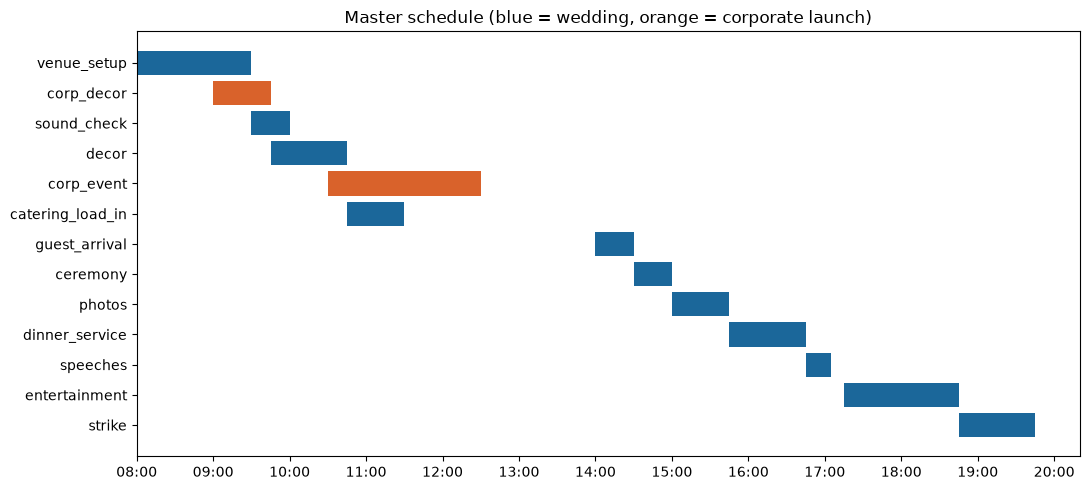

In [8]:
fig, ax = plt.subplots(figsize=(11, 5))
order = sorted(S, key=lambda a: S[a].start_minutes)
for i, aid in enumerate(order):
    s = S[aid]
    ax.barh(i, s.end_minutes - s.start_minutes, left=s.start_minutes,
            color="#1B679A" if by_id[aid].event_id == "wedding" else "#D9622B")
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.invert_yaxis()
ticks = range(8 * 60, max(s.end_minutes for s in S.values()) + 60, 60)
ax.set_xticks(list(ticks)); ax.set_xticklabels([hm(x) for x in ticks])
ax.set_title("Master schedule (blue = wedding, orange = corporate launch)"); plt.tight_layout(); plt.show()

**Break it on purpose (1): impossible fixed times.** Fix the ceremony at
13:00 — but it must come *after* guest arrival, which the client fixed at
14:00. No schedule can satisfy both. The solver must say so, and **name** the
conflicting activities (FR-03), not return a broken plan.

In [9]:
bad_events = build_demo_events()
for e in bad_events:
    for a in e.activities:
        if a.id == "ceremony":
            a.fixed_start_minutes = 13 * 60
bad = solve_planning_phase(bad_events, resources)
print("status:", bad.status_name, "| feasible:", bad.is_feasible)
print("conflicting fixed/locked activities named by the solver:", bad.conflicting_pinned_activity_ids)
assert not bad.is_feasible and {"ceremony", "guest_arrival"} <= set(bad.conflicting_pinned_activity_ids)
print("PASS: an impossible request is refused, with the cause named")

status: INFEASIBLE | feasible: False
conflicting fixed/locked activities named by the solver: ['ceremony', 'corp_event', 'guest_arrival']
PASS: an impossible request is refused, with the cause named


**Break it on purpose (2): a hand-edited schedule with three mistakes.**
(a) dinner starts during the photos, though it must wait for them; (b) the
speeches are given to the photographer, the wrong role; (c) the speeches are
also moved to the same time as the photos, so the photographer is
double-booked. The verifier must catch all three kinds.

*This check found a real gap:* the verifier first missed (b), because it only
checked timing and double-booking. It now also checks that every assigned
resource has the role the activity needs (FR-05).

In [10]:
broken = copy.deepcopy(S)
broken["dinner_service"].start_minutes = S["photos"].start_minutes + 10          # (a) too early
broken["dinner_service"].end_minutes = broken["dinner_service"].start_minutes + 60
broken["speeches"].start_minutes = S["photos"].start_minutes                      # (c) same time as photos
broken["speeches"].end_minutes = S["photos"].start_minutes + 20
broken["speeches"].assigned_resource_ids = ["photographer-1"]                     # (b) wrong role
found = verify_schedule(acts, resources, broken)
for c in found:
    print(f"  {c.type.value:<22} {c.message}")
kinds = {c.type.value for c in found}
assert {"precedence_violation", "wrong_assignment", "resource_overcommit"} <= kinds
print(f"PASS: the verifier caught all three kinds of mistake ({len(found)} problems in total)")

  precedence_violation   dinner_service starts at 910 but predecessor photos ends at 945 (+0 min lag): must start at or after 945
  precedence_violation   speeches starts at 900 but predecessor dinner_service ends at 970 (+0 min lag): must start at or after 970
  resource_overcommit    Resource photographer-1 (capacity 1) is committed to 2 activities at once: ['photos', 'speeches']
  wrong_assignment       speeches needs 1 x av_crew but has 0
  wrong_assignment       speeches is assigned photographer-1 (photographer), a role it does not need
PASS: the verifier caught all three kinds of mistake (5 problems in total)


**PSPLIB benchmark.** One of the 480 standard j30 instances (30 jobs, 4
resource types), converted and solved, then verified. The full run of all 480
is `python -m examples.validate_psplib` (100% feasible and conflict-free).

In [11]:
from scheduling_engine.psplib import parse_sm, to_scheduling_model
inst = parse_sm("data/psplib/j30/j3010_1.sm")
ev, res = to_scheduling_model(inst)
t = time.perf_counter()
sol = solve_planning_phase([ev], res, minimize_makespan=False)
print(f"{len(ev.activities)} activities, {len(res)} resource units | {sol.status_name} in {time.perf_counter() - t:.2f} s | makespan {sol.makespan_minutes}")
assert sol.is_feasible and verify_schedule(ev.activities, res, sol.activities) == []
print("PASS: PSPLIB instance solved and independently verified")

32 activities, 105 resource units | OPTIMAL in 0.41 s | makespan 165
PASS: PSPLIB instance solved and independently verified


## 2 · Digital twin

The twin holds the live state and compares it with the plan. Divergence =
more than the tolerance (10 min by default) away from plan. Two kinds of
evidence: a **late check-in**, or **no check-in at all** (the sensor-free signal).

In [12]:
def on_time(twin, until, skip=()):
    # Everyone due to start/finish by `until` checks in exactly on plan.
    for aid, s in sorted(S.items(), key=lambda kv: kv[1].start_minutes):
        if aid in skip:
            continue
        if s.start_minutes <= until and twin.state_of(aid).actual_start_minutes is None:
            twin.record_check_in(CheckIn(aid, CheckInType.STARTED, s.start_minutes))
        if s.end_minutes <= until and twin.state_of(aid).actual_end_minutes is None:
            twin.record_check_in(CheckIn(aid, CheckInType.COMPLETED, s.end_minutes))

twin = OperationalDigitalTwin(schedule, default_tolerance_minutes=10)
day_start = min(s.start_minutes for s in S.values())
t1 = S["venue_setup"].end_minutes
on_time(twin, t1)
print(f"everyone on time until {hm(t1)} → divergences:", twin.detect_divergence(t1))
assert twin.detect_divergence(t1) == []
print("PASS: on-time check-ins raise nothing")
# Leave one out: the corporate stage decor (planned 09:00) never checks in.
twin_x = OperationalDigitalTwin(schedule, default_tolerance_minutes=10)
on_time(twin_x, t1, skip={"corp_decor"})
print(f"stage decor silent → at {hm(t1)}:", [(d.activity_id, d.type.value, d.delta_minutes) for d in twin_x.detect_divergence(t1)])

everyone on time until 09:30 → divergences: []
PASS: on-time check-ins raise nothing
stage decor silent → at 09:30: [('corp_decor', 'missing_start_confirmation', 30)]


**A known delay:** catering checks in 40 minutes late. Check the reported delta by hand.

In [13]:
cat = S["catering_load_in"]
on_time(twin, cat.start_minutes + 40, skip={"catering_load_in"})
twin.record_check_in(CheckIn("catering_load_in", CheckInType.STARTED, cat.start_minutes + 40))
d = [x for x in twin.detect_divergence(cat.start_minutes + 40) if x.activity_id == "catering_load_in"]
print(d)
assert d[0].type.value == "start_time_deviation" and d[0].delta_minutes == 40   # 40 = check-in time − planned start
print("PASS: late start reported with delta = check-in − planned start = 40 min")

[Divergence(activity_id='catering_load_in', type=<DivergenceType.START_TIME_DEVIATION: 'start_time_deviation'>, planned_minutes=645, reference_minutes=685, delta_minutes=40)]
PASS: late start reported with delta = check-in − planned start = 40 min


**Silence:** a vendor that never checks in. Planned start of the ceremony is
14:30 (after guest arrival). Ask the twin at 14:35 (5 min late — inside
tolerance) and at 14:45 (15 min — outside).

In [14]:
cer = S["ceremony"].start_minutes
inside = [x for x in twin.detect_divergence(cer + 5) if x.activity_id == "ceremony"]
outside = [x for x in twin.detect_divergence(cer + 15) if x.activity_id == "ceremony"]
print("at +5 min:", inside); print("at +15 min:", outside)
assert inside == [] and outside[0].type.value == "missing_start_confirmation" and outside[0].delta_minutes == 15
print("PASS: no check-in is detected from silence alone — but only once past the tolerance")

at +5 min: []
at +15 min: [Divergence(activity_id='ceremony', type=<DivergenceType.MISSING_START_CONFIRMATION: 'missing_start_confirmation'>, planned_minutes=870, reference_minutes=885, delta_minutes=15)]
PASS: no check-in is detected from silence alone — but only once past the tolerance


## 3 · Cascade simulation (SimPy)

"What happens if we change nothing?" First a sanity check: simulate the day
with no disruption — no activity may come out *later* than planned.

In [15]:
fresh = OperationalDigitalTwin(schedule, default_tolerance_minutes=10)
base = simulate_cascade(acts, resources, schedule, fresh, day_start, {})
late = {k: v for k, v in base.delay_minutes.items() if v > 0}
print("activities later than plan with NO disruption:", late)
assert late == {}
print("PASS: undisturbed simulation delays nothing")

activities later than plan with NO disruption: {}
PASS: undisturbed simulation delays nothing


**A 20-minute overrun.** Everything on time until the photos start; the
photographer never confirms finishing, and it is now 20 minutes past the
planned end. By hand: dinner must wait for photos, so it starts 20 min late,
and everything chained after it moves too.

In [16]:
twin_c = OperationalDigitalTwin(schedule, default_tolerance_minutes=10)
for aid, s in sorted(S.items(), key=lambda kv: kv[1].start_minutes):
    if s.start_minutes < S["photos"].start_minutes:
        twin_c.record_check_in(CheckIn(aid, CheckInType.STARTED, s.start_minutes))
        twin_c.record_check_in(CheckIn(aid, CheckInType.COMPLETED, s.end_minutes))
twin_c.record_check_in(CheckIn("photos", CheckInType.STARTED, S["photos"].start_minutes))
now = S["photos"].end_minutes + 20
cascade = simulate_cascade(acts, resources, schedule, twin_c, now, {"photos": 20})
pd.DataFrame([dict(activity=a, planned_start=hm(S[a].start_minutes),
                   predicted_start=hm(cascade.predicted_activities[a].start_minutes),
                   delay_min=cascade.delay_minutes.get(a, 0)) for a in ["dinner_service", "speeches", "entertainment", "strike"]])

,activity,planned_start,predicted_start,delay_min
0,dinner_service,15:45,16:05,20
1,speeches,16:45,17:05,20
2,entertainment,17:15,17:35,20
3,strike,18:45,19:05,20


In [17]:
assert cascade.predicted_activities["dinner_service"].start_minutes == S["photos"].end_minutes + 20
assert all(cascade.delay_minutes[a] == 20 for a in ["dinner_service", "speeches", "entertainment", "strike"])
print("PASS: the cascade matches the hand reasoning: dinner, speeches, entertainment and strike all +20 min")

PASS: the cascade matches the hand reasoning: dinner, speeches, entertainment and strike all +20 min


## 4 · Re-optimisation

Re-plan only what hasn't started, keep fixed and locked times, and report
the cost signal for Component 4. Same photographer case first.

In [18]:
t = time.perf_counter()
r = reoptimize(acts, resources, schedule, twin_c, now, {"photos": 20}, time_limit_seconds=5)
print(f"feasible {r.is_feasible} | {r.status_name} | {time.perf_counter() - t:.3f} s (limit 5 s)")
print("cost signal:", r.cost_signal)
assert r.is_feasible and verify_schedule(acts, resources, r.schedule.activities) == []
assert all(r.schedule.activities[a].start_minutes == S[a].start_minutes
           for a in S if twin_c.state_of(a).state.value == "completed")
print("PASS: re-plan is conflict-free, finished activities untouched, under 5 s")

feasible True | OPTIMAL | 0.003 s (limit 5 s)
cost signal: CostSignal(total_delay_minutes=80, delayed_activity_ids=('dinner_service', 'entertainment', 'speeches', 'strike'), resource_overtime_minutes={'setup-1': 20, 'setup-2': 20, 'av-1': 20, 'catering-1': 20, 'catering-2': 20, 'photographer-1': 20})
PASS: re-plan is conflict-free, finished activities untouched, under 5 s


**Where re-optimising beats doing nothing — scenario B.** The setup crew
overruns; the AV crew is shared with the other client's launch, fixed at
10:30. Doing nothing would start it late. The re-plan should keep 10:30 by
moving the wedding's sound check after the launch.

In [19]:
ops = new_operations()
play_on_time(ops, **scenario_kwargs("setup_overrun", ops))
p = ops.pending_proposal
print("do nothing →", p.do_nothing_violations)
print("re-plan    →", [(c.activity_id, f"{hm(c.old_start)}→{hm(c.new_start)}") for c in p.changes], f"in {p.solve_seconds:.3f} s")
rev = p.revised.activities
assert p.do_nothing_violations and rev["corp_event"].start_minutes == 10 * 60 + 30
assert rev["sound_check"].start_minutes >= rev["corp_event"].end_minutes
assert rev["guest_arrival"].start_minutes == 14 * 60
print("PASS: doing nothing breaks the 10:30 launch; the re-plan keeps 10:30 and 14:00")

do nothing → ['corp_event has an externally fixed start of 630 but is scheduled at 640']
re-plan    → [('venue_setup', '08:00→08:00'), ('decor', '09:45→10:00'), ('sound_check', '09:30→12:40'), ('catering_load_in', '10:45→11:00')] in 0.006 s
PASS: doing nothing breaks the 10:30 launch; the re-plan keeps 10:30 and 14:00


**Break it on purpose (3): a lock that can't be kept.** Lock entertainment at
its planned time, then let the photos overrun by 2 hours. Nothing can keep the
lock — the re-optimiser must refuse and **name** it.

In [20]:
ops2 = new_operations()
ent = ops2.schedule.activities["entertainment"].start_minutes
ops2.lock("entertainment", ent, "you")
ph = ops2.schedule.activities["photos"]
play_on_time(ops2, ph.start_minutes, silent={"photos"})
ops2.check_in("photos", CheckInType.STARTED, ph.start_minutes)
ops2.tick(ph.end_minutes + 120)
p2 = ops2.pending_proposal
print("feasible:", p2.is_feasible, "| named:", p2.conflicting_locked_ids)
assert not p2.is_feasible and "entertainment" in p2.conflicting_locked_ids
print("PASS: an impossible lock is named, never silently broken")

feasible: False | named: ['entertainment']
PASS: an impossible lock is named, never silently broken


## 5 · Disruption evaluation (Objective 6)

The full study runs 200 random scenarios × 4 setups
(`python -m examples.evaluate_disruption_handling`, ~20 s). Here: 30 scenarios
of the "usable slack" setup, with **delay absorbed computed by hand**:

> delay absorbed = 1 − (how much later the day ends ÷ injected delay),
> counted only for conflict-free results.

In [21]:
from scheduling_engine.scenario_generation import generate_scenario, inject_disruption
from scheduling_engine.baselines import naive_forward_shift
from scheduling_engine.models import Schedule

def end(sch): return max(s.end_minutes for s in sch.activities.values())
rows = []
for seed in range(30):
    ev, res, sch = generate_scenario(seed, include_buffer=True, consumable_buffer=True)
    if not sch.is_feasible:
        continue
    sc = inject_disruption(ev, res, sch, seed)
    a = ev.activities
    outcomes = {
        "naive shift": naive_forward_shift(sch, sc.disrupted_activity_id, sc.injected_delay_minutes),
        "greedy": Schedule(True, simulate_cascade(a, res, sch, sc.twin, sc.now_minutes, sc.predicted_extra_duration_minutes).predicted_activities),
    }
    ro = reoptimize(a, res, sch, sc.twin, sc.now_minutes, sc.predicted_extra_duration_minutes)
    outcomes["CP re-optimise"] = ro.schedule if ro.is_feasible else None
    for name, out in outcomes.items():
        if out is None:
            rows.append(dict(seed=seed, strategy=name, result="proven impossible", absorbed=None)); continue
        ok = verify_schedule(a, res, out.activities) == []
        later = end(out) - end(sch)                      # how much later the day now ends
        absorbed = max(0.0, min(1.0, 1 - later / sc.injected_delay_minutes)) if ok else None
        rows.append(dict(seed=seed, strategy=name, injected=sc.injected_delay_minutes, ends_later_by=later,
                         result="conflict-free" if ok else "HIDDEN CONFLICT", absorbed=absorbed))
ev_df = pd.DataFrame(rows)
ev_df.head(9)

,seed,strategy,injected,ends_later_by,result,absorbed
0,0,naive shift,58.0,58.0,conflict-free,0.0
1,0,greedy,58.0,0.0,HIDDEN CONFLICT,NaN
2,0,CP re-optimise,NaN,NaN,proven impossible,NaN
3,1,naive shift,46.0,46.0,HIDDEN CONFLICT,NaN
4,1,greedy,46.0,26.0,HIDDEN CONFLICT,NaN
5,1,CP re-optimise,NaN,NaN,proven impossible,NaN
6,2,naive shift,15.0,15.0,HIDDEN CONFLICT,NaN
7,2,greedy,15.0,0.0,conflict-free,1.0
8,2,CP re-optimise,15.0,0.0,conflict-free,1.0


In [22]:
summary = ev_df.groupby("strategy").agg(
    scenarios=("seed", "count"),
    conflict_free=("result", lambda s: f"{100 * (s == 'conflict-free').mean():.0f}%"),
    hidden_conflicts=("result", lambda s: int((s == "HIDDEN CONFLICT").sum())),
    proven_impossible=("result", lambda s: int((s == "proven impossible").sum())),
    delay_absorbed=("absorbed", lambda s: f"{100 * s.dropna().mean():.0f}%"))
print("(30-scenario sample — the full 200-scenario run gives about 84% for CP re-optimise)")
summary

(30-scenario sample — the full 200-scenario run gives about 84% for CP re-optimise)


,scenarios,conflict_free,hidden_conflicts,proven_impossible,delay_absorbed
strategy,,,,,
CP re-optimise,30,60%,0,12,81%
greedy,30,53%,14,0,78%
naive shift,30,67%,10,0,0%


In [23]:
cp = ev_df[ev_df.strategy == "CP re-optimise"]
assert (cp.result != "HIDDEN CONFLICT").all()
print("PASS: CP re-optimise never returned a hidden conflict: every result is conflict-free or proven impossible")
one = cp.dropna(subset=["absorbed"]).iloc[0]
print(f"worked example, seed {int(one.seed)}: injected {int(one.injected)} min, day ends {int(one.ends_later_by)} min later "
      f"→ absorbed = 1 − {int(one.ends_later_by)}/{int(one.injected)} = {one.absorbed:.2f}")

PASS: CP re-optimise never returned a hidden conflict: every result is conflict-free or proven impossible
worked example, seed 2: injected 15 min, day ends 0 min later → absorbed = 1 − 0/15 = 1.00


## 6 · The live service

The same loop the dashboard uses: a disruption becomes a **proposal**;
nothing changes until the planner confirms (FR-13); then the cost signal,
notifications and audit log follow.

In [24]:
live = new_operations()
play_on_time(live, **scenario_kwargs("silent_photographer", live))
prop = live.pending_proposal
print(f"proposal #{prop.id}: {len(prop.changes)} activities would move | schedule version still {live.schedule_version}")
assert live.schedule_version == 1
print("PASS: nothing changed yet — the planner decides")
live.confirm(prop.id, "you", "client agreed")
print("after confirm → version", live.schedule_version, "| Component 4 received:", live.component4.received[-1]["cost_signal"])
print(f"{len(live.notifications.outbox)} notifications, e.g.: {live.notifications.outbox[0].message}")
assert live.schedule_version == 2 and live.component4.received
print("PASS: confirmed plan applied; cost signal published; staff notified")

proposal #1: 5 activities would move | schedule version still 1
PASS: nothing changed yet — the planner decides
after confirm → version 2 | Component 4 received: {'total_delay_minutes': 80, 'delayed_activity_ids': ['dinner_service', 'entertainment', 'speeches', 'strike'], 'resource_overtime_minutes': {'setup-1': 20, 'setup-2': 20, 'av-1': 20, 'catering-1': 20, 'catering-2': 20, 'photographer-1': 20}}
7 notifications, e.g.: Schedule change: Photography session now 15:00-16:05 (was 15:00-15:45).
PASS: confirmed plan applied; cost signal published; staff notified


In [25]:
pd.DataFrame([dict(seq=e.sequence, time=hm(e.event_minute), kind=e.kind, who=e.actor, what=e.summary)
              for e in live.audit.entries if e.kind != "checkin.received"])

,seq,time,kind,who,what
0,1,08:00,schedule.planned,system,"Master schedule planned: 13 activities, 0 conf..."
1,19,16:05,disruption.detected,system,Photography session: missing completion confir...
2,20,16:05,disruption.detected,system,Dinner service: missing start confirmation (+2...
3,21,16:05,proposal.created,system,Proposal #1: do nothing ends 20:05 with 0 rule...
4,22,16:05,schedule.changed,planner:you,"Proposal #1 confirmed: schedule v2, 5 activiti..."
5,23,16:05,cost_signal.issued,system,Cost signal sent to Component 4: 80 delay-minu...


**Stale proposals are thrown away.** If a new check-in arrives while a proposal is waiting, that proposal was computed on old facts — it must be superseded.

In [26]:
s2 = new_operations()
play_on_time(s2, **scenario_kwargs("silent_photographer", s2))
first = s2.pending_proposal
s2.check_in("photos", CheckInType.COMPLETED)        # the photographer finally confirms
print("first proposal is now:", first.status)
assert first.status == "superseded"
print("PASS: a proposal built on old facts can't be confirmed")

first proposal is now: superseded
PASS: a proposal built on old facts can't be confirmed


## 7 · Scalability (NFR-04)

5 concurrent events × 30 activities, 160 resources (each event's 30 plus a
shared pool of 10). Plan the day, then time five disruptions end to end
(detect + simulate + re-optimise). The full test is
`python -m examples.scalability_test` (worst 0.215 s over 60 disruptions).

In [27]:
import random
from examples.scalability_test import plan_day, run_trial
base_ops, plan_s, plan_conflicts = plan_day(0, 5, False)
print(f"planned {len(base_ops.activities)} activities, {len(base_ops.resources)} resources in {plan_s:.2f} s, {plan_conflicts} conflicts")
rng = random.Random(7)
trials = [run_trial(base_ops, rng) for _ in range(5)]
pd.DataFrame([dict(activity=t["activity"], overrun=t["overrun"], seconds=round(t["latency_seconds"], 3),
                   outcome=t["outcome"], revised_conflicts=t["revised_conflicts"]) for t in trials])

planned 150 activities, 160 resources in 0.44 s, 0 conflicts


,activity,overrun,seconds,outcome,revised_conflicts
0,ev2-a28,24,0.026,proposal,0
1,ev3-a12,56,0.107,proposal,0
2,ev1-a07,19,0.080,proposal,0
3,ev4-a10,21,0.185,proposal,0
4,ev3-a06,52,0.131,proposal,0


In [28]:
assert plan_conflicts == 0 and all(t["latency_seconds"] < 5 for t in trials)
assert all((t["revised_conflicts"] or 0) == 0 for t in trials)
print(f"PASS: worst {max(t['latency_seconds'] for t in trials):.3f} s against the 5 s limit, 0 conflicts")

PASS: worst 0.185 s against the 5 s limit, 0 conflicts


## Summary

If every check printed PASS, you have checked yourself that:

1. the planner obeys every rule (checked by hand), refuses impossible fixed
   times and names them, and the verifier catches a hand-broken schedule;
2. the twin detects late check-ins and missing check-ins, only past the tolerance;
3. the simulation delays nothing on a normal day and reproduces the
   hand-reasoned cascade for an overrun;
4. re-optimisation keeps finished work fixed, protects the other client's
   10:30 launch, and names an impossible lock;
5. CP re-optimise never returns a hidden conflict, and delay absorbed is
   computed exactly as defined;
6. the live service waits for the planner, then publishes the cost signal,
   notifications and an audit trail, and discards stale proposals;
7. a 5-event day re-plans far inside 5 seconds.

The phone page's offline queue has its own tests: `node tests/js/test_checkin_queue.mjs`.
All 76 Python tests: `python -m pytest`.